# Resolución orientativa de la práctica de la semana 3
600 líneas sintéticas, una observación por línea: 300 de entrenamiento, 100 de calibración y 200 de prueba. Las seis variables representan minutos, gigabytes y mensajes en franjas de día y noche durante una ventana de 30 días. La columna cambio_simulado identifica alteraciones del generador solo para evaluación; nunca se utiliza como entrada. Los conjuntos están separados por entidad. No contienen etiquetas de cancelación ni series longitudinales.
Ejecuta desde la carpeta Recursos. La propuesta es una solución posible; compara configuraciones y justifica tus decisiones.

## Datos incluidos en el propio notebook
Ejecuta las celdas en orden dentro de una carpeta de trabajo. La primera genera los CSV sintéticos; no necesitas descargar datos. Puedes conservar esa celda sin ejecutar si quieres analizar tus propias copias de los archivos.

In [1]:
# Generación de los datos sintéticos de consumo y conexiones.
import numpy as np
import pandas as pd
from itertools import combinations
rng = np.random.default_rng(42)
# Avance de la secuencia para reproducir la referencia original del curso.
rng.standard_normal(1800)
filas = []
for i in range(600):
    particion = "entrenamiento" if i < 300 else (
        "calibracion" if i < 400 else "prueba")
    uso = rng.lognormal(0, .22)
    valores = np.array([120, 70, 4, 2.5, 55, 35]) * uso
    valores += rng.normal(0, [10, 8, .5, .3, 6, 4])
    cambio = particion == "prueba" and i % 10 == 0
    if cambio:
        valores[[0, 1, 4, 5]] *= .15
        valores[[2, 3]] *= 2.5
    filas.append([f"L{i+1:04}", particion,
                  *np.maximum(valores, 0).round(3), int(cambio)])
columnas = ["linea_id", "particion", "min_dia", "min_noche", "gb_dia",
            "gb_noche", "sms_dia", "sms_noche", "cambio_simulado"]
pd.DataFrame(filas, columns=columnas).to_csv("comportamiento_lineas.csv", index=False)
aristas = list(combinations([f"L{i:02d}" for i in range(1, 5)], 2))
aristas += list(combinations([f"L{i:02d}" for i in range(7, 11)], 2))
aristas += [("L04", "L05"), ("L05", "L06"), ("L06", "L07")]
pd.DataFrame(aristas, columns=["origen", "destino"]).to_csv(
    "conexiones_lineas.csv", index=False)


Umbral de calibración: 0.2263600859686445
linea_id  cambio_simulado  error_reconstruccion  alerta
   L0491                1             17.150601    True
   L0451                1             16.963651    True
   L0581                1             16.651701    True
   L0571                1             16.290225    True
   L0561                1             15.656722    True
   L0401                1             13.876177    True
   L0511                1             12.338311    True
   L0471                1             11.189695    True
   L0551                1             10.927337    True
   L0521                1             10.635576    True
   L0591                1              9.383577    True
   L0431                1              9.304639    True
   L0531                1              9.280079    True
   L0501                1              9.056319    True
   L0541                1              8.217687    True
   L0481                1              7.748415    True
   L04

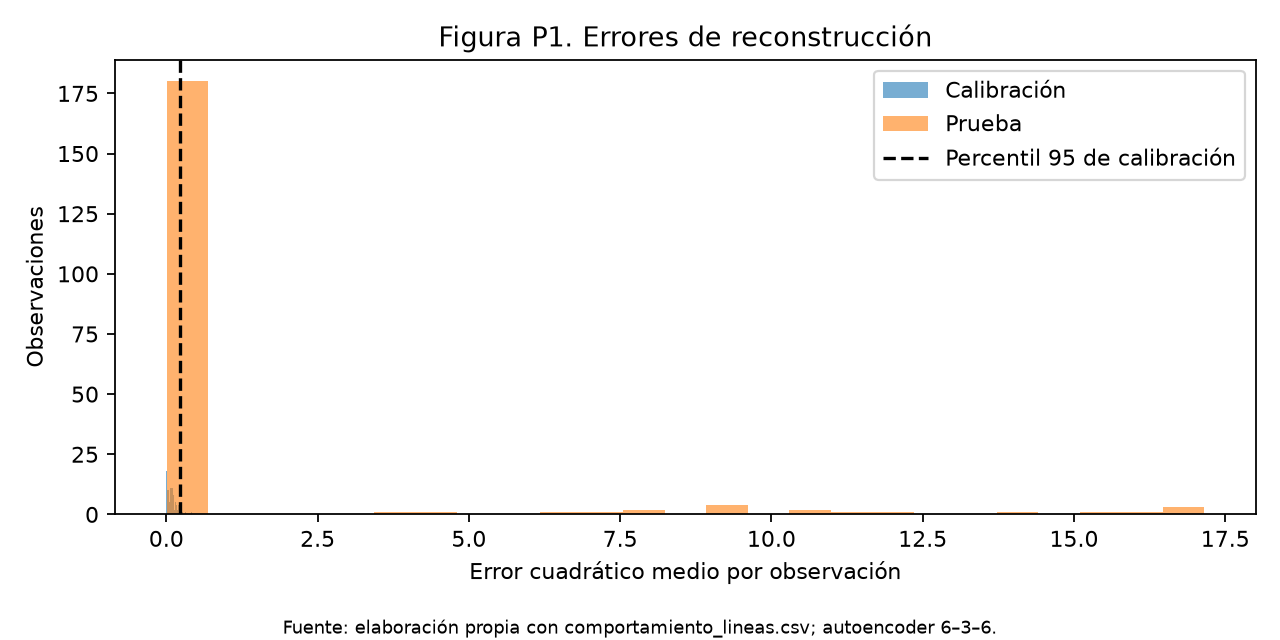

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
df = pd.read_csv("comportamiento_lineas.csv")
variables = ["min_dia","min_noche","gb_dia","gb_noche","sms_dia","sms_noche"]
tr = df.particion.eq("entrenamiento")
cal = df.particion.eq("calibracion")
te = df.particion.eq("prueba")
escalador = StandardScaler().fit(df.loc[tr,variables])
Xtr = escalador.transform(df.loc[tr,variables])
Xcal = escalador.transform(df.loc[cal,variables])
Xte = escalador.transform(df.loc[te,variables])
ae = MLPRegressor(hidden_layer_sizes=(3,),activation="tanh",solver="lbfgs",
                  max_iter=2000,random_state=42,alpha=.01)
ae.fit(Xtr,Xtr)
error_cal = np.mean((Xcal-ae.predict(Xcal))**2,axis=1)
umbral = np.quantile(error_cal,.95)
error_te = np.mean((Xte-ae.predict(Xte))**2,axis=1)
resultado = df.loc[te,["linea_id","cambio_simulado"]].copy()
resultado["error_reconstruccion"] = error_te
resultado["alerta"] = error_te > umbral
print("Umbral de calibración:",umbral)
print(resultado.sort_values("error_reconstruccion",ascending=False).head(20).to_string(index=False))
# La etiqueta simulada nunca entró al entrenamiento ni a la calibración.
print(pd.crosstab(resultado.cambio_simulado,resultado.alerta))
pca=PCA(n_components=3).fit(Xtr)
error_pca=np.mean((Xte-pca.inverse_transform(pca.transform(Xte)))**2)
print("MSE prueba, PCA:",error_pca,"AE:",error_te.mean())
print("Estas alertas detectan desviaciones de la referencia; no predicen cancelaciones.")
resultado.to_csv("resultado_alertas.csv",index=False)

# Evidencia separada para calibración y prueba.
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(error_cal,bins=25,alpha=.6,label="Calibración")
ax.hist(error_te,bins=25,alpha=.6,label="Prueba")
ax.axvline(umbral,color="black",linestyle="--",label="Percentil 95 de calibración")
ax.set(xlabel="Error cuadrático medio por observación",ylabel="Observaciones",title="Figura P1. Errores de reconstrucción")
ax.legend();fig.text(.5,.01,"Fuente: elaboración propia con comportamiento_lineas.csv; autoencoder 6–3–6.",ha="center",fontsize=8)
fig.tight_layout(rect=(0,.05,1,1));fig.savefig("errores_reconstruccion.png",dpi=160);plt.close(fig)
print("Filas por partición:",df.particion.value_counts().to_dict())
print("Resumen por partición:\n",df.groupby("particion")[variables].agg(["mean","std"]))
for estado in [True,False]:
    print("Ejemplo con alerta =",estado)
    print(resultado[resultado.alerta.eq(estado)].head(1).to_string(index=False))


## Interpretación orientativa
La ejecución de referencia recupera los 20 cambios simulados y marca también 19 de los 180 registros sin cambio: precisión 20/39 ≈ 0,513, recuperación 1 y tasa de falsas alertas 19/180 ≈ 0,106. Son resultados condicionados al generador, la partición, el modelo y el umbral; no son estimaciones de rendimiento en clientes reales. El percentil 95 en calibración no obliga a que la prueba tenga exactamente un 5 % de falsas alertas.

En esta ejecución, PCA obtiene menor error cuadrático medio global de reconstrucción que el autoencoder. Esto impide afirmar que la red mejora automáticamente la representación. Tampoco demuestra por sí solo que PCA sea mejor detector: esa comparación requeriría calibrar un umbral propio para PCA con el conjunto de calibración y evaluar ambos detectores sobre las mismas observaciones de prueba.

No hay cancelaciones observadas ni trayectorias temporales. Investigar anticipación de cancelaciones exigiría fechas de emisión de alertas, ventanas históricas anteriores a esas fechas, cancelaciones posteriores y un horizonte definido. La separación temporal tendría que impedir el uso de información futura. El prototipo actual solo ilustra desviaciones respecto de una referencia sintética.


## Complemento introductorio de grafos
Carga conexiones_lineas.csv y construye un grafo simple no dirigido de 10 nodos y 15 aristas. Dibuja la red, calcula centralidad de grado e intermediación normalizada y compara dos nodos en 3–5 frases. Cada enlace representa una conexión simulada sin dirección ni frecuencia. El pequeño grafo es un recurso independiente del CSV del autoencoder; no se deduce de sus variables de consumo. Alcance orientativo: 15 minutos, sin embeddings ni nuevos modelos.

Tabla P3. Centralidades del grafo sintético
nodo  grado  centralidad_grado  intermediacion
 L05      2             0.2222          0.5556
 L06      2             0.2222          0.5556
 L04      4             0.4444          0.5000
 L07      4             0.4444          0.5000
 L01      3             0.3333          0.0000
 L02      3             0.3333          0.0000
 L03      3             0.3333          0.0000
 L08      3             0.3333          0.0000
 L09      3             0.3333          0.0000
 L10      3             0.3333          0.0000
Fuente: elaboración propia con conexiones_lineas.csv y NetworkX.
Nodos: 10 Aristas: 15
Cada arista representa una conexión simulada; se omiten dirección y frecuencia.
Las centralidades describen esta red; no demuestran influencia comercial ni fraude.


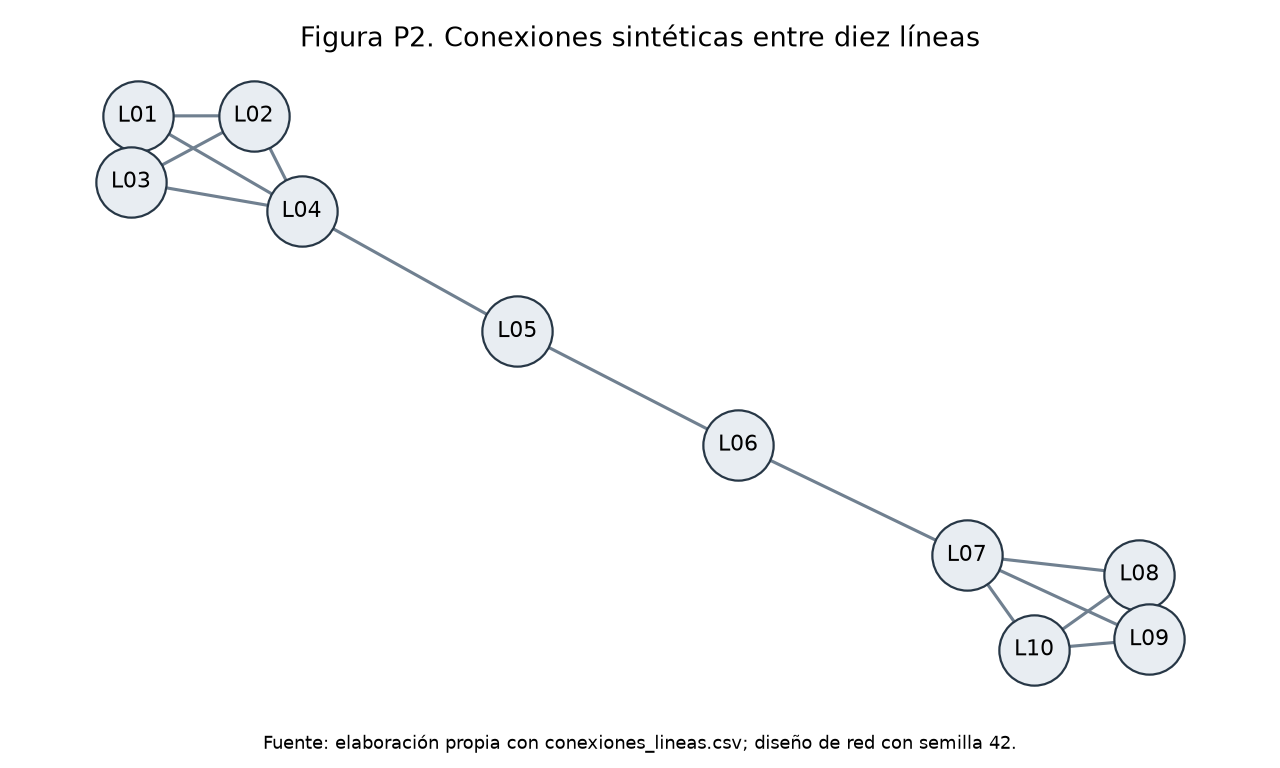

In [3]:
# Complemento breve: grafo simple, no dirigido y sin pesos.
import networkx as nx
aristas = pd.read_csv("conexiones_lineas.csv")
assert not aristas.isna().any().any()
assert not aristas.origen.eq(aristas.destino).any()
G = nx.from_pandas_edgelist(aristas, source="origen", target="destino", create_using=nx.Graph())
assert G.number_of_nodes() == 10 and G.number_of_edges() == 15
centralidad_grado = nx.degree_centrality(G)
centralidad_intermediacion = nx.betweenness_centrality(G, normalized=True, weight=None)
centralidades = pd.DataFrame({"nodo": sorted(G.nodes)})
centralidades["grado"] = centralidades.nodo.map(dict(G.degree()))
centralidades["centralidad_grado"] = centralidades.nodo.map(centralidad_grado)
centralidades["intermediacion"] = centralidades.nodo.map(centralidad_intermediacion)
centralidades = centralidades.sort_values(["intermediacion", "nodo"], ascending=[False, True])
print("Tabla P3. Centralidades del grafo sintético")
print(centralidades.round(4).to_string(index=False))
print("Fuente: elaboración propia con conexiones_lineas.csv y NetworkX.")
print("Nodos:", G.number_of_nodes(), "Aristas:", G.number_of_edges())
centralidades.to_csv("resultado_centralidades.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.8))
pos = nx.spring_layout(G, seed=42)
nx.draw_networkx(G, pos, ax=ax, node_color="#e8edf2", edgecolors="#273746",
                 edge_color="#708090", node_size=1000, font_size=10, width=1.4)
ax.set_title("Figura P2. Conexiones sintéticas entre diez líneas")
ax.set_axis_off()
fig.text(.5, .025, "Fuente: elaboración propia con conexiones_lineas.csv; diseño de red con semilla 42.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, .05, 1, 1))
fig.savefig("grafo_lineas.png", dpi=160)
plt.close(fig)
print("Cada arista representa una conexión simulada; se omiten dirección y frecuencia.")
print("Las centralidades describen esta red; no demuestran influencia comercial ni fraude.")


## Solución orientativa del complemento
Complemento orientativo: L04 tiene cuatro vecinos, centralidad de grado 0,4444 e intermediación 0,5000; L05 tiene dos vecinos, grado normalizado 0,2222 e intermediación 0,5556. L04 destaca por conectividad local, mientras L05 forma parte del enlace entre dos zonas densas y aparece en más caminos mínimos entre otros nodos. Tener más contactos no equivale a ocupar la mayor posición de intermediación. Los resultados dependen de omitir dirección y frecuencia; no permiten deducir influencia comercial, fraude ni cancelaciones. La figura y la tabla reproducibles están en el notebook.